# Практична робота №10
## Неперервні розподіли в `scipy.stats`

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тема:** Нормальний розподіл, параметри μ та σ, функції `pdf()`, `cdf()`, `ppf()`.

**Мета роботи:** згенерувати вибірку із 30 денних температур на основі липневої середньомісячної температури Дніпра, підібрати нормальну модель за вибіркою, зіставити гістограму з кривою густини та розрахувати ймовірність і квантиль.

> Навчальні значення температур синтетичні; результати не є прогнозом погоди.

### Підготовка: бібліотеки та вихідні дані

За таблицею **варіанта №5 (Дніпро)** температури за 12 місяців: −4, −3, 3, 11, 17, 21, **23**, 22, 16, 9, 3, −2 °C. Липень — 7-й місяць, у Python має індекс `6`. Для генерації встановлюємо `seed=5` — номер варіанта.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Дані Дніпра з Практики 1: січень ... грудень.
monthly_temps = np.array([-4, -3, 3, 11, 17, 21, 23, 22, 16, 9, 3, -2])
city = "Дніпро"
variant = 5
july_temp = monthly_temps[6]
print(f"Місто: {city}; варіант: №{variant}")
print(f"Липнева середньомісячна температура: {july_temp} °C")

Місто: Дніпро; варіант: №5
Липнева середньомісячна температура: 23 °C


## Завдання 1. Побудова вибірки денних температур

Генеруємо 30 температур за нормальним законом із центром `23 °C` і заданим під час генерації стандартним відхиленням `2.5 °C`. Після генерації обчислюємо **фактичні вибіркові** середнє та стандартне відхилення: вони необов'язково збігаються з параметрами генератора.

In [2]:
np.random.seed(variant)
daily_temps = np.random.normal(loc=july_temp, scale=2.5, size=30)

print("30 згенерованих денних температур, °C:")
print(np.round(daily_temps, 2))
print("Кількість спостережень:", daily_temps.size)
print(f"Середнє вибірки: {daily_temps.mean():.4f} °C")
print(f"Стандартне відхилення вибірки (ddof=0): {daily_temps.std():.4f} °C")
print(f"Липневе значення з таблиці: {july_temp} °C")
print(f"Відхилення середнього вибірки від табличного: {daily_temps.mean() - july_temp:+.4f} °C")

assert daily_temps.shape == (30,)

30 згенерованих денних температур, °C:
[24.1  22.17 29.08 22.37 23.27 26.96 20.73 21.52 23.47 22.18 20.02 22.49
 22.1  24.51 18.84 21.25 25.88 27.64 19.22 24.61 20.55 20.86 20.82 21.94
 25.49 24.78 23.15 22.09 23.01 22.74]
Кількість спостережень: 30
Середнє вибірки: 22.9277 °C
Стандартне відхилення вибірки (ddof=0): 2.3745 °C
Липневе значення з таблиці: 23 °C
Відхилення середнього вибірки від табличного: -0.0723 °C


**Пояснення.** Вибіркове середнє близьке до 23 °C, але не точно 23 °C, оскільки ми отримали лише одну випадкову реалізацію з 30 значень. `np.random.seed(5)` забезпечує повторюваність цієї конкретної реалізації.

## Завдання 2. Параметри нормального розподілу

Для підбору моделі використовуємо **середнє і стандартне відхилення отриманих 30 значень**, а не початкові `23` і `2.5`. Метод `.std()` у NumPy за замовчуванням має `ddof=0`, як у прикладі практики.

In [3]:
mean = daily_temps.mean()
std = daily_temps.std()
dist = stats.norm(loc=mean, scale=std)

print(f"Оцінка параметра μ = {mean:.4f} °C")
print(f"Оцінка параметра σ = {std:.4f} °C")
print(f"Підібрана модель: N(μ={mean:.4f}, σ={std:.4f})")
assert std > 0

Оцінка параметра μ = 22.9277 °C
Оцінка параметра σ = 2.3745 °C
Підібрана модель: N(μ=22.9277, σ=2.3745)


## Завдання 3. Гістограма та теоретична PDF-крива

Будуємо гістограму з `density=True`, щоби вертикальна вісь показувала **густину**, а не кількість днів: тільки за цієї умови накладання `dist.pdf(x)` змістовне. Візьмемо 7 інтервалів, враховуючи невеликий розмір вибірки.

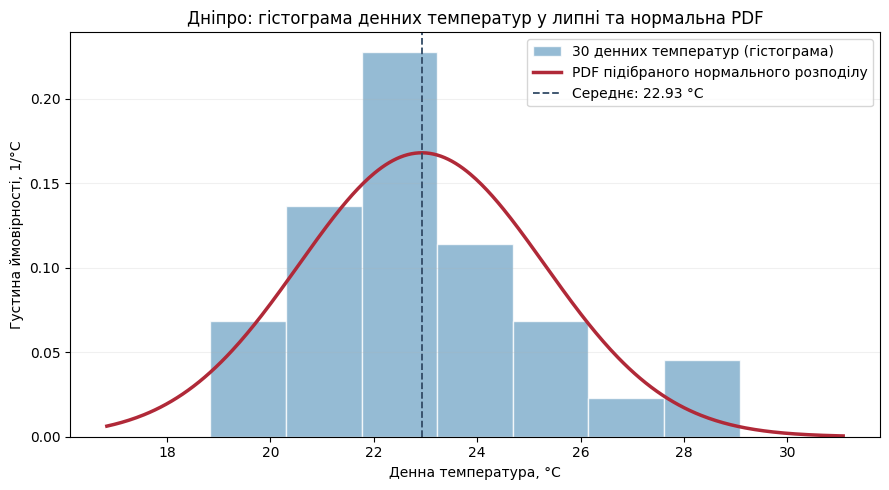

In [4]:
x = np.linspace(daily_temps.min() - 2, daily_temps.max() + 2, 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    daily_temps, bins=7, density=True,
    color="#78a8c9", edgecolor="white", alpha=0.78,
    label="30 денних температур (гістограма)"
)
ax.plot(x, dist.pdf(x), color="#b02938", linewidth=2.5,
        label="PDF підібраного нормального розподілу")
ax.axvline(mean, color="#324b66", linestyle="--", linewidth=1.3,
           label=f"Середнє: {mean:.2f} °C")
ax.set_xlabel("Денна температура, °C")
ax.set_ylabel("Густина ймовірності, 1/°C")
ax.set_title("Дніпро: гістограма денних температур у липні та нормальна PDF")
ax.legend()
ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
plt.show()

**Візуальний висновок.** Підібрана крива проходить поблизу центральної частини гістограми, де зосереджено більшість спостережень. Висоти окремих стовпців не повторюють плавну криву точно: з 30 випадкових вимірів гістограма має помітні локальні нерівності. Це очікувано і не свідчить саме по собі про помилку побудови моделі.

## Завдання 4. Ймовірність у межах одного стандартного відхилення

За нормальною моделлю обчислюємо

\[
P(\mu - \sigma \leq X \leq \mu + \sigma)
= F(\mu+\sigma)-F(\mu-\sigma),
\]

де `F` — накопичена функція розподілу (`cdf`). Окремо рахуємо **фактичну частку** згенерованих температур у тому самому інтервалі: вона може відрізнятися від теоретичної ймовірності.

In [5]:
lower = mean - std
upper = mean + std
probability = dist.cdf(upper) - dist.cdf(lower)
inside = (daily_temps >= lower) & (daily_temps <= upper)
empirical_count = int(inside.sum())
empirical_share = inside.mean()

print(f"Межі інтервалу: [{lower:.4f}; {upper:.4f}] °C")
print(f"Теоретична ймовірність за CDF: {probability:.6f} ({probability:.2%})")
print(f"Частка у вибірці: {empirical_count}/30 = {empirical_share:.6f} ({empirical_share:.2%})")
print("Правило 68–95–99.7: теоретично приблизно 68% у межах ±1σ")
assert np.isclose(probability, 0.6826894921370859)

Межі інтервалу: [20.5532; 25.3022] °C
Теоретична ймовірність за CDF: 0.682689 (68.27%)
Частка у вибірці: 21/30 = 0.700000 (70.00%)
Правило 68–95–99.7: теоретично приблизно 68% у межах ±1σ


**Пояснення.** Теоретична ймовірність для **будь-якого** нормального розподілу в межах `μ ± σ` дорівнює приблизно **68,27%**, отже відповідає правилу 68–95–99,7. Для цих 30 згенерованих температур усередині інтервалу лежить **21 із 30**, тобто **70%**. Ця невелика розбіжність виникає через скінченний розмір випадкової вибірки. Важливо не плутати **модельну ймовірність** з **емпіричною часткою**.

## Завдання 5. 95-й процентиль через `ppf()`

Виклик `dist.ppf(0.95)` знаходить таку температуру `t`, для якої `dist.cdf(t) = 0.95`. Це межа верхніх 5% температур **за підібраною моделлю**.

In [6]:
q95 = dist.ppf(0.95)
check_cdf = dist.cdf(q95)
print(f"95-й процентиль: {q95:.4f} °C")
print(f"Контроль: CDF({q95:.4f} °C) = {check_cdf:.6f} ({check_cdf:.2%})")
print(f"P(X > {q95:.4f} °C) = {1-check_cdf:.2%}")
assert np.isclose(check_cdf, 0.95)

95-й процентиль: 26.8335 °C
Контроль: CDF(26.8335 °C) = 0.950000 (95.00%)
P(X > 26.8335 °C) = 5.00%


**Інтерпретація.** За підібраною нормальною моделлю приблизно 95% денних температур не перевищують **26,83 °C**, а 5% — перевищують цю межу. Функція `cdf(температура)` повертає накопичену ймовірність; обернена до неї `ppf(ймовірність)` повертає температуру, що відповідає заданій накопиченій ймовірності.

## Контрольні питання — письмові відповіді

**1. Яка різниця між `.pdf(x)` та `.cdf(x)`?**

- **`pdf(x)`** повертає **густину ймовірності** в точці `x`. Це не ймовірність потрапляння в одну конкретну точку: для неперервної величини ймовірність рівно одного значення дорівнює нулю. Площа під PDF на інтервалі дорівнює ймовірності потрапляння в цей інтервал.
- **`cdf(x)`** повертає **накопичену ймовірність** `P(X ≤ x)`, тобто ймовірність не перевищити значення `x`. Тому `cdf(b) - cdf(a)` дає ймовірність потрапляння в `[a, b]`.

**2. Чому `.pdf(x)` іноді може перевищувати 1?**

PDF є **густиною**, а не ймовірністю, тож її значення може перевищувати 1, якщо розподіл достатньо вузький. Наприклад, для нормального розподілу зі стандартним відхиленням `σ = 0.2` густина в центрі становить `1 / (0.2 × √(2π)) ≈ 1.995`. Проте **повна площа під кривою** дорівнює 1; тому жодна ймовірність інтервалу не перевищує 1.

**3. Чому `.ppf()` — обернена до `.cdf()`?**

- `.cdf(x)` приймає **значення випадкової величини** (тут — температуру, °C) й повертає **ймовірність** у діапазоні від 0 до 1.
- `.ppf(p)` приймає **накопичену ймовірність** (наприклад, `p = 0.95`) й повертає **відповідне значення температури**. Для нашого розподілу `ppf(0.95) ≈ 26.83 °C`, а `cdf(26.83 °C) ≈ 0.95`.

Таким чином, для неперервного нормального розподілу виконується `cdf(ppf(p)) = p` для `0 < p < 1`.

## Висновок

На прикладі липневих температур Дніпра (варіант №5) створено відтворювану синтетичну вибірку з 30 значень, оцінено параметри нормальної моделі за вибірковими середнім і стандартним відхиленням та зіставлено гістограму густини з `pdf`. Через різницю значень `cdf` обчислено ймовірність у межах одного стандартного відхилення й підтверджено правило приблизно 68%. Через `ppf` знайдено поріг 95-го процентиля. Практичні результати і теоретичні пояснення наведено для всіх п'яти завдань.